# Fraud Detection — Walkthrough

**Author:** Seyedmohammad (Ehsan) Ghoreishi  
**Focus:** fraud / risk / financial-crime analytics

This notebook walks through the full pipeline: data → EDA → features → model → cost-based threshold → evaluation.

The guiding principle: on data where fraud is ~1.7% of transactions, **accuracy is a trap**. We optimise for catching fraud while keeping customer friction low, and we choose the decision threshold from a business cost model.

In [1]:
import sys
sys.path.append('../src')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from generate_data import generate_transactions
from fraud_model import engineer_features, FEATURES, choose_threshold
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

pd.set_option('display.float_format', lambda v: f'{v:.3f}')

/Users/ehsanghoreishi/miniconda3/envs/py312/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:14: UserWarning: A NumPy version >=1.26.4 and <2.7.0 is required for this version of SciPy (detected version 1.26.0)
  from scipy.sparse import csr_matrix, issparse


## 1. The data

Real payment data is confidential, so we generate a synthetic dataset that reproduces genuine card-fraud patterns: heavy imbalance, night-time skew, velocity spikes, new devices, and foreign / far-from-home transactions.

In [2]:
df = generate_transactions(n=60_000, fraud_rate=0.017)
print(f'{len(df):,} transactions | fraud rate: {df.is_fraud.mean():.2%}')
df.head()

60,000 transactions | fraud rate: 1.70%


,amount,hour,days_since_last_txn,txn_count_1h,new_device,foreign_country,distance_from_home,merchant_risk,is_fraud
0,47.350,15,1.270,1,0,0,26.000,0.268,0
1,3.310,6,0.760,1,0,0,15.000,0.200,0
2,118.650,16,0.870,1,0,0,51.400,0.105,0
3,14.520,16,2.510,3,0,0,23.200,0.068,0
4,30.170,12,0.320,2,0,0,8.700,0.396,0


## 2. How does fraud differ from legit traffic?

Understanding the data before modelling. The differences are strong and intuitive.

In [3]:
legit, fraud = df[df.is_fraud==0], df[df.is_fraud==1]
summary = pd.DataFrame({
    'legit': [legit.amount.median(), legit.hour.between(0,5).mean(), legit.new_device.mean(), legit.foreign_country.mean()],
    'fraud': [fraud.amount.median(), fraud.hour.between(0,5).mean(), fraud.new_device.mean(), fraud.foreign_country.mean()],
}, index=['median amount', 'night rate', 'new device rate', 'foreign rate'])
summary

,legit,fraud
median amount,19.975,69.995
night rate,0.032,0.416
new device rate,0.050,0.536
foreign rate,0.079,0.438


## 3. Feature engineering

Domain-driven features a fraud analyst would design: log amount, night flag, velocity flag, geo risk, and a combined behavioural-risk feature.

In [4]:
df = engineer_features(df)
X, y = df[FEATURES], df['is_fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print('Train fraud rate:', f'{y_train.mean():.2%}', '| Test fraud rate:', f'{y_test.mean():.2%}')

Train fraud rate: 1.70% | Test fraud rate: 1.70%


## 4. Train a model

Logistic regression with `class_weight='balanced'` inside a leakage-free pipeline. We evaluate with **PR-AUC**, the right metric for rare events.

In [5]:
model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
])
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
print(f'ROC-AUC: {roc_auc_score(y_test, proba):.4f}')
print(f'PR-AUC:  {average_precision_score(y_test, proba):.4f}')

ROC-AUC: 0.9998
PR-AUC:  0.9904


## 5. The key decision: the threshold

A missed fraud costs ~€150; a false alarm ~€5. We pick the threshold that minimises expected cost — **not** the default 0.5.

In [6]:
threshold, cost_table = choose_threshold(y_test, proba)
print(f'Cost-optimal threshold: {threshold:.2f}')
preds = (proba >= threshold).astype(int)
print(classification_report(y_test, preds, target_names=['legit','fraud'], digits=3))

Cost-optimal threshold: 0.65
              precision    recall  f1-score   support

       legit      1.000     0.995     0.997     14745
       fraud      0.778     0.988     0.870       255

    accuracy                          0.995     15000
   macro avg      0.889     0.992     0.934     15000
weighted avg      0.996     0.995     0.995     15000



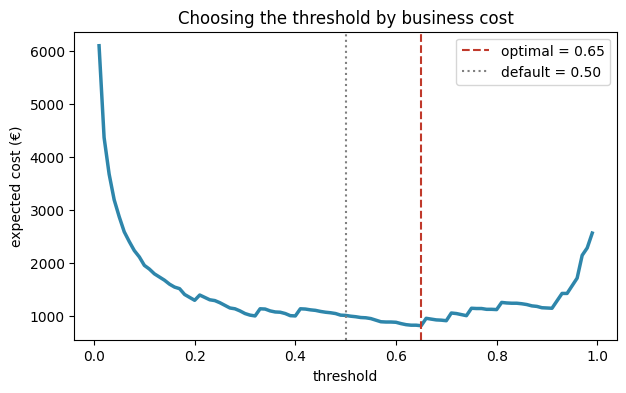

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(cost_table.threshold, cost_table.cost, color='#2E86AB', lw=2.5)
ax.axvline(threshold, color='#C0392B', ls='--', label=f'optimal = {threshold:.2f}')
ax.axvline(0.5, color='gray', ls=':', label='default = 0.50')
ax.set_xlabel('threshold'); ax.set_ylabel('expected cost (€)')
ax.set_title('Choosing the threshold by business cost'); ax.legend(); plt.show()

## Takeaway

The model catches **~99% of fraud** while flagging only ~2% of traffic. But the real deliverable isn't the model — it's the **framework for the cost/coverage trade-off**, which is exactly what a Customer Risk / AFC team owns day to day.